# TRABAJO FINAL – SISTEMA DE DETECCIÓN DE RIESGO DE DESERCIÓN ESTUDIANTIL

**Curso:** Fundamentos y Algoritmia para Inteligencia Artificial  
**Caso práctico:** Detección temprana de riesgo de deserción estudiantil mediante Machine Learning  
**Instructor:** Ing. Gunar Castro Iñigo  
**Integrantes:** _(completar con los nombres del equipo)_

> **Nota:** el dataset usado es **sintético con comportamiento realista**. No contiene información real de estudiantes.

**Contenido del cuaderno:** Etapa 1 conocer los datos · Etapa 2 preprocesamiento · Etapa 3 álgebra lineal · Etapa 4 estadística · Etapa 5 valores atípicos · Etapa 6 visualización · Etapa 7 modelo · Etapa 8 interpretación del riesgo · Guardado del modelo para Flask.

In [1]:
# Librerías principales
import warnings, json, os, datetime
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta del proyecto: blanco-gris y azul eléctrico
AZUL, AZUL_OSC, GRIS, GRIS_CLARO = "#1A56FF", "#0B2A8A", "#8A94A6", "#E6E9F0"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": GRIS_CLARO, "grid.color": GRIS_CLARO,
                                      "axes.titleweight": "bold", "figure.dpi": 110})
os.makedirs("../05_DOCUMENTACION/graficos", exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"../05_DOCUMENTACION/graficos/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


# ETAPA 1 – CONOCER LOS DATOS

Antes de entrenar cualquier modelo hay que entender con qué información se trabaja. Primero se **observa**, sin eliminar ni transformar nada.

In [2]:
ruta = "../02_DATASET/dataset_riesgo_desercion_estudiantil.csv"
df = pd.read_csv(ruta)
df.head(10)

,id_estudiante,sede,programa,turno,semestre,edad,promedio_academico,asistencia_pct,faltas_mes,tardanzas_mes,...,satisfaccion_formacion_1a5,trabaja_actualmente,horas_trabajo_semana,distancia_centro_km,tiempo_traslado_min,situacion_pago,calidad_conectividad,apoyo_familiar,riesgo_referencial,abandono
0,EST-0001,Independencia,Desarrollo de Software,Noche,5,24,13.4,97.6,1,3,...,4.0,No,0,12.4,59,1 cuota pendiente,Regular,Medio,Bajo,0
1,EST-0002,San Juan de Lurigancho,Desarrollo de Software,Tarde,2,24,15.5,80.0,4,2,...,4.0,Sí,28,24.1,81,1 cuota pendiente,Buena,Alto,Bajo,0
2,EST-0003,Lima Norte,Diseño y Desarrollo Web,Mañana,1,18,15.0,85.0,4,4,...,3.0,No,0,14.0,44,Al día,Buena,Alto,Bajo,0
3,EST-0004,San Juan de Lurigancho,Ingeniería de Software con IA,Tarde,4,22,18.0,85.1,4,1,...,4.0,No,0,4.1,16,Al día,Regular,Alto,Bajo,0
4,EST-0005,Huancayo,Redes y Seguridad Informática,Mañana,2,23,14.3,NaN,2,4,...,3.0,Sí,46,11.8,66,Al día,Regular,Alto,Medio,0
5,EST-0006,Arequipa,Diseño y Desarrollo Web,Noche,3,23,14.8,100.0,0,4,...,3.0,No,0,11.8,58,Al día,Buena,Alto,Bajo,0
6,EST-0007,San Juan de Lurigancho,Soporte y Mantenimiento,Mañana,3,26,9.9,100.0,0,2,...,4.0,Sí,11,2.9,28,1 cuota pendiente,Buena,Alto,Bajo,0
7,EST-0008,San Juan de Lurigancho,Desarrollo de Software,Noche,3,23,9.9,90.8,1,2,...,5.0,Sí,19,11.7,36,2 o más cuotas pendientes,Buena,Medio,Medio,1
8,EST-0009,Independencia,Ingeniería de Software con IA,Noche,4,19,14.3,73.8,6,0,...,4.0,No,0,24.6,77,Al día,Regular,Medio,Bajo,0
9,EST-0010,Independencia,Ingeniería de Software con IA,Mañana,5,26,11.7,90.7,1,4,...,2.0,Sí,41,4.6,28,Al día,Regular,Medio,Bajo,0


In [3]:
print("Dimensiones del dataset (filas, columnas):", df.shape)

print("\nTipos de datos:")
print(df.dtypes)

print("\nValores nulos por variable:")
nulos = df.isnull().sum()
print(nulos[nulos > 0])
print("\nTotal de valores nulos:", int(nulos.sum()))
print("Porcentaje máximo de nulos en una columna: %.2f %%" % (df.isnull().mean().max() * 100))

print("\nDistribución de la variable objetivo (abandono):")
conteo = df["abandono"].value_counts()
print(conteo)
print((df["abandono"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

Dimensiones del dataset (filas, columnas): (600, 24)

Tipos de datos:
id_estudiante                     str
sede                              str
programa                          str
turno                             str
semestre                        int64
edad                            int64
promedio_academico            float64
asistencia_pct                float64
faltas_mes                      int64
tardanzas_mes                   int64
cursos_desaprobados             int64
horas_estudio_semana          float64
uso_plataforma_horas          float64
tutorias_mes                    int64
satisfaccion_formacion_1a5    float64
trabaja_actualmente               str
horas_trabajo_semana            int64
distancia_centro_km           float64
tiempo_traslado_min             int64
situacion_pago                    str
calidad_conectividad              str
apoyo_familiar                    str
riesgo_referencial                str
abandono                        int64
dtype: object

Val

### Interpretación – Etapa 1

- El dataset tiene **600 registros y 24 columnas**: 1 identificador, 14 variables numéricas, 7 categóricas, la variable `riesgo_referencial` y la variable objetivo `abandono`.
- Existen **48 valores nulos** repartidos en 7 columnas (`promedio_academico`, `asistencia_pct`, `horas_estudio_semana`, `uso_plataforma_horas`, `satisfaccion_formacion_1a5`, `calidad_conectividad`, `apoyo_familiar`). Ninguna pasa del 1,5 % de sus filas, así que conviene **imputar** y no eliminar registros (se perderían datos útiles de un dataset ya pequeño).
- **El dataset NO está balanceado**: 500 estudiantes continúan (83,3 %) y 100 abandonan (16,7 %), una proporción cercana a 5 a 1. Por eso `accuracy` engaña: un modelo que siempre responda "continúa" tendría 83 % de aciertos sin detectar a nadie en riesgo. Se usarán `stratify=y`, `class_weight="balanced"` y se priorizará el **recall** de la clase abandono.

In [4]:
# ¿Qué variables podrían estar relacionadas con la deserción?
numericas_todas = df.select_dtypes("number").drop(columns="abandono")
corr_obj = numericas_todas.corrwith(df["abandono"]).sort_values()
print("Correlación de cada variable numérica con 'abandono':")
print(corr_obj.round(3))

print("\nTasa de abandono (%) por categoría:")
for col in ["sede", "programa", "turno", "trabaja_actualmente", "situacion_pago", "calidad_conectividad", "apoyo_familiar"]:
    print(f"\n{col}")
    print((df.groupby(col)["abandono"].mean() * 100).round(1).sort_values(ascending=False).to_string())

Correlación de cada variable numérica con 'abandono':
promedio_academico           -0.221
asistencia_pct               -0.169
horas_estudio_semana         -0.079
tiempo_traslado_min          -0.075
distancia_centro_km          -0.071
edad                         -0.064
tutorias_mes                 -0.060
uso_plataforma_horas         -0.031
satisfaccion_formacion_1a5   -0.012
semestre                     -0.002
tardanzas_mes                 0.008
horas_trabajo_semana          0.034
cursos_desaprobados           0.055
faltas_mes                    0.199
dtype: float64

Tasa de abandono (%) por categoría:

sede
sede
Arequipa                  22.9
Lima Norte                21.8
Trujillo                  17.3
Huancayo                  12.5
Independencia             11.9
San Juan de Lurigancho    11.8

programa
programa
Desarrollo de Software           20.1
Diseño y Desarrollo Web          17.6
Soporte y Mantenimiento          17.2
Redes y Seguridad Informática    14.7
Ingeniería de Software

### ¿Qué variables parecen relacionadas con la deserción?

- **Numéricas:** `promedio_academico` (correlación −0,22), `faltas_mes` (+0,20) y `asistencia_pct` (−0,17) son las más asociadas. Menor promedio, menor asistencia y más faltas van con mayor abandono.
- **Categóricas:** `apoyo_familiar` Bajo (26,0 % de abandono frente a 12,8 % con apoyo Alto), `situacion_pago` con 2 o más cuotas pendientes (28,0 % frente a 14,5 % al día), `calidad_conectividad` Limitada (25,9 %) y algunas sedes (Arequipa 22,9 % y Lima Norte 21,8 % frente a ~12 % en otras).
- Las correlaciones individuales son **moderadas a bajas**: ninguna variable explica el abandono por sí sola. Es un problema donde la señal está repartida entre varios factores, lo que justifica un modelo multivariable.

# ETAPA 2 – LIMPIEZA Y PREPROCESAMIENTO

Decisiones tomadas:

| Decisión | Justificación |
|---|---|
| Excluir `id_estudiante` | Es un identificador, no aporta información predictiva |
| Excluir `riesgo_referencial` | Fue construida como referencia; usarla sería **fuga de información** |
| Nulos numéricos → **mediana** | Robusta frente a valores extremos |
| Nulos categóricos → **moda** | Mantiene la categoría más frecuente |
| Numéricas → **StandardScaler** | La regresión logística es sensible a la escala de las variables |
| Categóricas → **OneHotEncoder** | Convierte categorías en columnas 0/1 sin imponer un orden falso |
| `stratify=y` en el split | Conserva la proporción 83/17 en entrenamiento y prueba |

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df.drop(columns=["abandono", "riesgo_referencial", "id_estudiante"])
y = df["abandono"]
print("Variables predictoras:", X.shape, "| Variable objetivo:", y.shape)

# 1. Separación de numéricas y categóricas
cols_num = X.select_dtypes(include="number").columns.tolist()
cols_cat = [c for c in X.columns if c not in cols_num]
print("\nNuméricas (%d):" % len(cols_num), cols_num)
print("Categóricas (%d):" % len(cols_cat), cols_cat)

# 2 a 4. Imputación, normalización y codificación dentro de un ColumnTransformer
transf_num = Pipeline([("imputar", SimpleImputer(strategy="median")),
                       ("escalar", StandardScaler())])
transf_cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                       ("codificar", OneHotEncoder(handle_unknown="ignore"))])
preprocesador = ColumnTransformer([("num", transf_num, cols_num),
                                   ("cat", transf_cat, cols_cat)])

# 5. Entrenamiento / prueba estratificado (80 % / 20 %)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("\nEntrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Proporción de abandono en entrenamiento: %.3f | en prueba: %.3f" % (y_train.mean(), y_test.mean()))

Variables predictoras: (600, 21) | Variable objetivo: (600,)

Numéricas (14): ['semestre', 'edad', 'promedio_academico', 'asistencia_pct', 'faltas_mes', 'tardanzas_mes', 'cursos_desaprobados', 'horas_estudio_semana', 'uso_plataforma_horas', 'tutorias_mes', 'satisfaccion_formacion_1a5', 'horas_trabajo_semana', 'distancia_centro_km', 'tiempo_traslado_min']
Categóricas (7): ['sede', 'programa', 'turno', 'trabaja_actualmente', 'situacion_pago', 'calidad_conectividad', 'apoyo_familiar']



Entrenamiento: (480, 21) | Prueba: (120, 21)
Proporción de abandono en entrenamiento: 0.167 | en prueba: 0.167


### Interpretación – Etapa 2

El `ColumnTransformer` se **ajusta únicamente con los datos de entrenamiento** (dentro del `Pipeline`), por lo que la mediana, la media y las categorías se aprenden sin ver el conjunto de prueba. Así se evita la fuga de datos. El split estratificado mantiene 16,7 % de abandono en ambos conjuntos (480 filas de entrenamiento con 80 abandonos y 120 de prueba con 20 abandonos).

# ETAPA 3 – ÁLGEBRA LINEAL APLICADA

Se usan vectores y matrices con datos reales del proyecto. Cada estudiante es un **vector** de indicadores y el conjunto de estudiantes es una **matriz** (filas = estudiantes, columnas = variables).

In [6]:
cols_alg = ["promedio_academico", "asistencia_pct", "faltas_mes", "cursos_desaprobados"]

# 1. Matriz con varias observaciones (5 estudiantes sin datos faltantes)
M = df[cols_alg].dropna().head(5).to_numpy()
print("Matriz de 5 estudiantes x 4 indicadores:")
print(M)
print("Forma de la matriz:", M.shape)

# 2. Suma y resta de vectores
est_a, est_b = M[0], M[1]
print("\nEstudiante A:", est_a)
print("Estudiante B:", est_b)
print("A + B (acumulado de indicadores):", est_a + est_b)
print("A - B (diferencia entre perfiles):", est_a - est_b)

# 3. Producto punto: puntaje ponderado de un estudiante
pesos = np.array([0.35, 0.40, -0.10, -0.15])
print("\nProducto punto A · pesos:", np.dot(est_a, pesos))

# 4. Norma del vector y distancia entre perfiles
print("Norma de A:", np.linalg.norm(est_a))
print("Distancia entre A y B (norma de A - B):", np.linalg.norm(est_a - est_b))

# 5. Producto matriz-vector: puntaje de los 5 estudiantes a la vez
print("\nPuntajes ponderados de los 5 estudiantes (M @ pesos):")
print(M @ pesos)

Matriz de 5 estudiantes x 4 indicadores:
[[ 13.4  97.6   1.    1. ]
 [ 15.5  80.    4.    2. ]
 [ 15.   85.    4.    0. ]
 [ 18.   85.1   4.    1. ]
 [ 14.8 100.    0.    0. ]]
Forma de la matriz: (5, 4)

Estudiante A: [13.4 97.6  1.   1. ]
Estudiante B: [15.5 80.   4.   2. ]
A + B (acumulado de indicadores): [ 28.9 177.6   5.    3. ]
A - B (diferencia entre perfiles): [-2.1 17.6 -3.  -1. ]

Producto punto A · pesos: 43.480000000000004
Norma de A: 98.52573267933612
Distancia entre A y B (norma de A - B): 18.00472160295737

Puntajes ponderados de los 5 estudiantes (M @ pesos):
[43.48  36.725 38.85  39.79  45.18 ]


### Interpretación – Álgebra lineal (con mis palabras)

- **Matriz de observaciones:** cada fila es un estudiante y cada columna un indicador. Es exactamente la forma en que scikit-learn recibe los datos (`X`).
- **Suma y resta de vectores:** sumar acumula indicadores; restar muestra **en qué se diferencian dos perfiles** indicador por indicador.
- **Producto punto:** multiplica cada indicador por su peso y suma. Es la operación central de la regresión logística: el modelo calcula `w · x + b` antes de convertirlo en probabilidad. Los pesos negativos para faltas y cursos desaprobados hacen que empeoren el puntaje.
- **Norma:** es la "longitud" del vector, una medida de magnitud global. La norma de `A − B` es la **distancia entre dos estudiantes**: cuanto menor, más parecidos son sus perfiles.
- **Matriz por vector (`M @ pesos`):** aplica el producto punto a todos los estudiantes de una sola vez, por eso los modelos procesan miles de registros rápidamente.

In [7]:
# 6. Sistema de ecuaciones lineales con np.linalg.solve()
# Contexto: un tutor usa un puntaje de seguimiento = a*promedio + b*(asistencia/10) + c*faltas.
# Se conoce el puntaje de 3 estudiantes y se quiere recuperar los pesos a, b, c.
A = df[["promedio_academico", "asistencia_pct", "faltas_mes"]].dropna().head(3).to_numpy().astype(float)
A[:, 1] = A[:, 1] / 10          # asistencia en escala de 0 a 10
pesos_reales = np.array([0.5, 0.3, -0.4])
b = A @ pesos_reales             # puntajes conocidos de los 3 estudiantes

print("Matriz de coeficientes A:")
print(A.round(2))
print("Vector de puntajes b:", b.round(3))
print("Determinante de A:", round(np.linalg.det(A), 4), "(distinto de 0 → el sistema tiene solución única)")

solucion = np.linalg.solve(A, b)
print("\nSolución encontrada (a, b, c):", solucion.round(4))
print("¿Coincide con los pesos originales?", np.allclose(solucion, pesos_reales))

Matriz de coeficientes A:
[[13.4   9.76  1.  ]
 [15.5   8.    4.  ]
 [15.    8.5   4.  ]]
Vector de puntajes b: [9.228 8.55  8.45 ]
Determinante de A: -34.57 (distinto de 0 → el sistema tiene solución única)

Solución encontrada (a, b, c): [ 0.5  0.3 -0.4]
¿Coincide con los pesos originales? True


### Interpretación – Sistema de ecuaciones

Tres estudiantes dan tres ecuaciones con tres incógnitas (`a`, `b`, `c`). Como el **determinante es distinto de cero**, la matriz es invertible y existe una única solución, que `np.linalg.solve()` obtiene sin invertir la matriz explícitamente. La solución recupera los pesos originales (0,5; 0,3; −0,4), lo que confirma que el cálculo es correcto. En Machine Learning este mismo principio aparece al **ajustar los pesos de un modelo** a partir de los datos, aunque ahí hay más observaciones que incógnitas y se resuelve por optimización.

# ETAPA 4 – ANÁLISIS ESTADÍSTICO

Se calculan media, mediana, varianza y desviación estándar. La varianza y la desviación se obtienen **manualmente** (función propia) y con **NumPy**, y se comparan.

In [8]:
def varianza_manual(datos):
    datos = np.array(datos, dtype=float)
    media = np.sum(datos) / len(datos)
    return np.sum((datos - media) ** 2) / (len(datos) - 1)   # varianza muestral

def desviacion_manual(datos):
    return np.sqrt(varianza_manual(datos))

variables = ["promedio_academico", "asistencia_pct", "horas_estudio_semana", "tiempo_traslado_min"]
filas = []
for v in variables:
    d = df[v].dropna().to_numpy()
    filas.append({
        "variable": v,
        "media": np.mean(d),
        "mediana": np.median(d),
        "varianza_manual": varianza_manual(d),
        "varianza_numpy": np.var(d, ddof=1),
        "desv_manual": desviacion_manual(d),
        "desv_numpy": np.std(d, ddof=1),
        "coinciden": np.isclose(varianza_manual(d), np.var(d, ddof=1)) and np.isclose(desviacion_manual(d), np.std(d, ddof=1)),
    })
tabla_estadistica = pd.DataFrame(filas).set_index("variable").round(3)
tabla_estadistica

,media,mediana,varianza_manual,varianza_numpy,desv_manual,desv_numpy,coinciden
variable,,,,,,,
promedio_academico,13.736,13.7,5.907,5.907,2.431,2.431,True
asistencia_pct,83.576,84.3,112.383,112.383,10.601,10.601,True
horas_estudio_semana,10.388,10.5,15.989,15.989,3.999,3.999,True
tiempo_traslado_min,40.452,38.0,388.001,388.001,19.698,19.698,True


### Interpretación – Estadística

- Los resultados **manuales y los de NumPy coinciden exactamente** (columna `coinciden = True`). Se usó `ddof=1` (varianza muestral), porque los 600 estudiantes son una muestra.
- **Promedio académico:** media ≈ 13,74 y mediana ≈ 13,7, casi iguales, lo que indica una distribución **simétrica**; desviación ≈ 2,43 puntos.
- **Asistencia:** media ≈ 83,6 % con desviación ≈ 10,6; hay estudiantes por debajo del 60 %, que son los más preocupantes.
- **Horas de estudio:** media ≈ 10,4 h/semana y desviación ≈ 4,0: **gran variabilidad** entre estudiantes (de 1 a 22,6 h).
- **Tiempo de traslado:** la media (≈ 40,5 min) es mayor que la mediana (38 min), señal de **cola a la derecha** por estudiantes con trayectos muy largos.
- La **desviación estándar** está en las mismas unidades que la variable (puntos, %, horas, minutos), por eso es más fácil de interpretar que la varianza, que está en unidades al cuadrado.

# ETAPA 5 – VALORES ATÍPICOS

Se aplican dos técnicas: **IQR** (límites Q1 − 1,5·IQR y Q3 + 1,5·IQR) y **z-score** (|z| > 3). No se elimina nada automáticamente: primero se analiza si el valor es una situación real.

In [9]:
resumen = []
atipicos_idx = {}
for v in variables:
    s = df[v].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask_iqr = (s < lim_inf) | (s > lim_sup)
    z = (s - s.mean()) / s.std(ddof=1)
    mask_z = z.abs() > 3
    atipicos_idx[v] = s[mask_iqr].index
    resumen.append({"variable": v, "Q1": q1, "Q3": q3, "límite inf.": lim_inf, "límite sup.": lim_sup,
                    "atípicos IQR": int(mask_iqr.sum()), "atípicos z>3": int(mask_z.sum()),
                    "mín": s.min(), "máx": s.max()})
pd.DataFrame(resumen).set_index("variable").round(2)

,Q1,Q3,límite inf.,límite sup.,atípicos IQR,atípicos z>3,mín,máx
variable,,,,,,,,
promedio_academico,12.2,15.4,7.40,20.20,3,1,6.3,20.0
asistencia_pct,75.5,91.8,51.05,116.25,0,0,52.9,100.0
horas_estudio_semana,7.8,13.1,-0.15,21.05,2,1,1.0,22.6
tiempo_traslado_min,26.0,53.0,-14.50,93.50,11,6,10.0,114.0


In [10]:
# ¿Son valores imposibles o situaciones reales? Revisamos los extremos y su tasa de abandono.
for v in ["promedio_academico", "tiempo_traslado_min"]:
    sub = df.loc[atipicos_idx[v], ["id_estudiante", v, "sede", "abandono"]]
    print(f"\n{v}: {len(sub)} atípicos (IQR) | abandono entre ellos: {sub['abandono'].mean()*100:.0f} %")
    print(sub.sort_values(v).to_string(index=False))


promedio_academico: 3 atípicos (IQR) | abandono entre ellos: 33 %
id_estudiante  promedio_academico                   sede  abandono
     EST-0572                 6.3             Lima Norte         1
     EST-0395                 7.0 San Juan de Lurigancho         0
     EST-0184                 7.1               Arequipa         0

tiempo_traslado_min: 11 atípicos (IQR) | abandono entre ellos: 18 %
id_estudiante  tiempo_traslado_min                   sede  abandono
     EST-0016                   94               Trujillo         0
     EST-0383                   94 San Juan de Lurigancho         0
     EST-0417                   95             Lima Norte         1
     EST-0485                   96 San Juan de Lurigancho         0
     EST-0479                   98               Arequipa         0
     EST-0037                  100          Independencia         0
     EST-0062                  101          Independencia         0
     EST-0099                  103 San Juan de Lurig

### Interpretación – Valores atípicos y decisión

- `asistencia_pct` no tiene atípicos (el rango 52,9 % – 100 % es coherente).
- `promedio_academico` tiene 3 atípicos por IQR, todos **promedios muy bajos** (entre 6,3 y 7,1), y `horas_estudio_semana` tiene 2 (estudiantes con más de 21 h semanales).
- `tiempo_traslado_min` concentra la mayoría (11 por IQR, 6 por z-score): son trayectos de hasta 114 minutos.
- **Decisión: no eliminarlos.** Todos son valores **posibles en la realidad** (un estudiante con promedio muy bajo, o que vive lejos de la sede, es justo el perfil que interesa detectar). Eliminarlos haría perder los casos de mayor riesgo. El `StandardScaler` y la regularización de la regresión logística limitan su influencia sobre el modelo.

# ETAPA 6 – VISUALIZACIÓN DE DATOS

Cada gráfico tiene título, ejes etiquetados e interpretación. Se guardan también en `05_DOCUMENTACION/graficos/` para el informe.

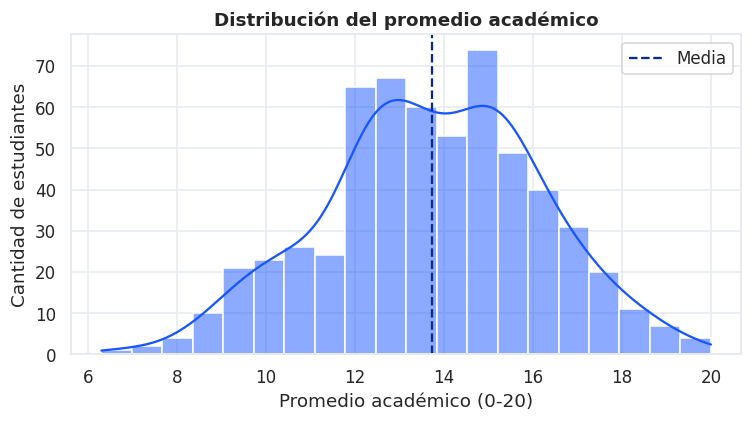

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["promedio_academico"].dropna(), bins=20, kde=True, color=AZUL, ax=ax)
ax.axvline(df["promedio_academico"].mean(), color=AZUL_OSC, ls="--", label="Media")
ax.set_title("Distribución del promedio académico"); ax.set_xlabel("Promedio académico (0-20)"); ax.set_ylabel("Cantidad de estudiantes")
ax.legend(); guardar("01_hist_promedio")

**Interpretación:** la distribución es aproximadamente normal y centrada cerca de 13,7. Pocos estudiantes tienen promedios menores a 9: son la minoría de mayor atención académica.

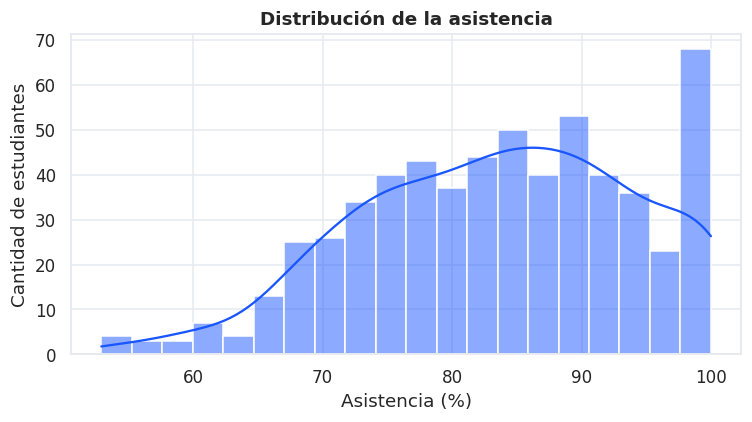

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["asistencia_pct"].dropna(), bins=20, kde=True, color=AZUL, ax=ax)
ax.set_title("Distribución de la asistencia"); ax.set_xlabel("Asistencia (%)"); ax.set_ylabel("Cantidad de estudiantes")
guardar("02_hist_asistencia")

**Interpretación:** la asistencia se concentra entre 75 % y 95 %, con una cola hacia valores bajos. El límite 100 % genera acumulación en el extremo derecho. La cola izquierda marca estudiantes con baja presencia en clase.

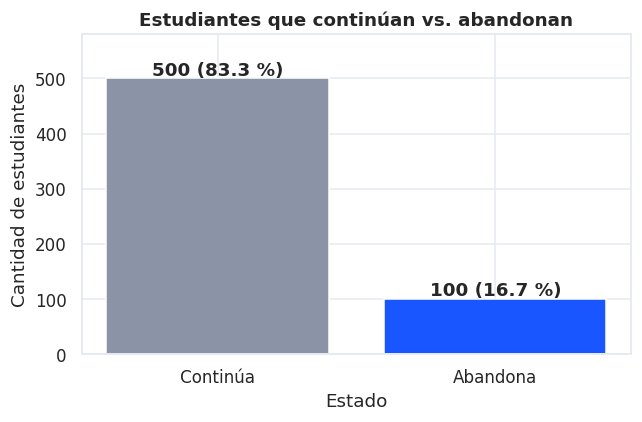

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
cuentas = df["abandono"].map({0: "Continúa", 1: "Abandona"}).value_counts()
bars = ax.bar(cuentas.index, cuentas.values, color=[GRIS, AZUL])
for b_, v_ in zip(bars, cuentas.values):
    ax.text(b_.get_x() + b_.get_width()/2, v_ + 6, f"{v_} ({v_/len(df)*100:.1f} %)", ha="center", fontweight="bold")
ax.set_title("Estudiantes que continúan vs. abandonan"); ax.set_ylabel("Cantidad de estudiantes"); ax.set_xlabel("Estado")
ax.set_ylim(0, 580); guardar("03_barras_abandono")

**Interpretación:** el desbalance 5 a 1 es evidente. Confirma que se debe evaluar con recall y F1 y no solo con accuracy.

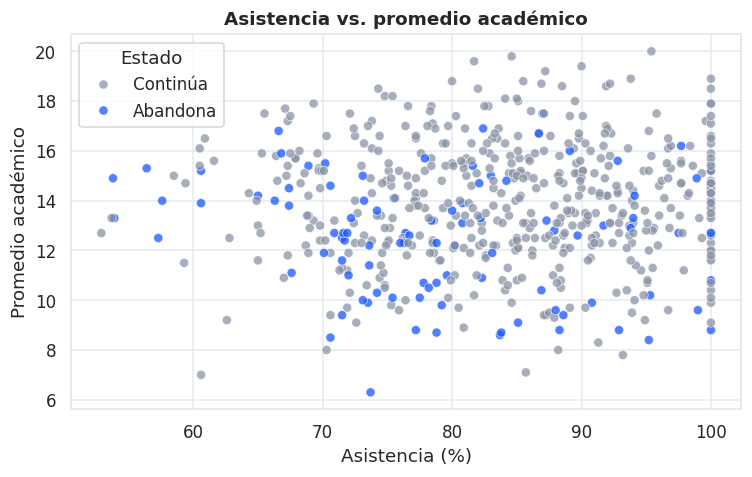

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
tmp = df.dropna(subset=["asistencia_pct", "promedio_academico"]).copy()
tmp["Estado"] = tmp["abandono"].map({0: "Continúa", 1: "Abandona"})
sns.scatterplot(data=tmp, x="asistencia_pct", y="promedio_academico", hue="Estado",
                palette={"Continúa": GRIS, "Abandona": AZUL}, alpha=0.75, ax=ax)
ax.set_title("Asistencia vs. promedio académico"); ax.set_xlabel("Asistencia (%)"); ax.set_ylabel("Promedio académico")
guardar("04_dispersion_asistencia_promedio")

**Interpretación:** asistencia y promedio **casi no están relacionados** (correlación ≈ 0,02): se puede tener buena asistencia y bajo promedio, o al revés. Por eso aportan información distinta al modelo. Los puntos azules (abandono) aparecen algo más en la zona de bajo promedio, pero se mezclan con los demás: ninguna variable separa las clases por sí sola.

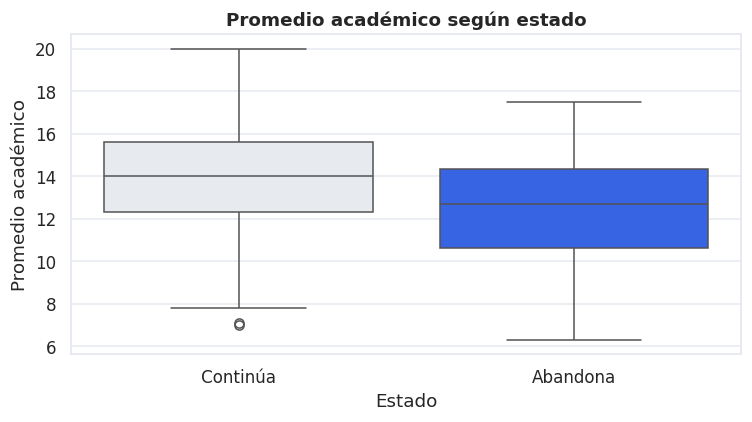

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x=df["abandono"].map({0: "Continúa", 1: "Abandona"}), y="promedio_academico",
            palette=[GRIS_CLARO, AZUL], ax=ax)
ax.set_title("Promedio académico según estado"); ax.set_xlabel("Estado"); ax.set_ylabel("Promedio académico")
guardar("05_boxplot_promedio")

**Interpretación:** la mediana del promedio es menor en quienes abandonan. Se observan algunos puntos fuera de los bigotes (atípicos) que se conservan por ser casos reales.

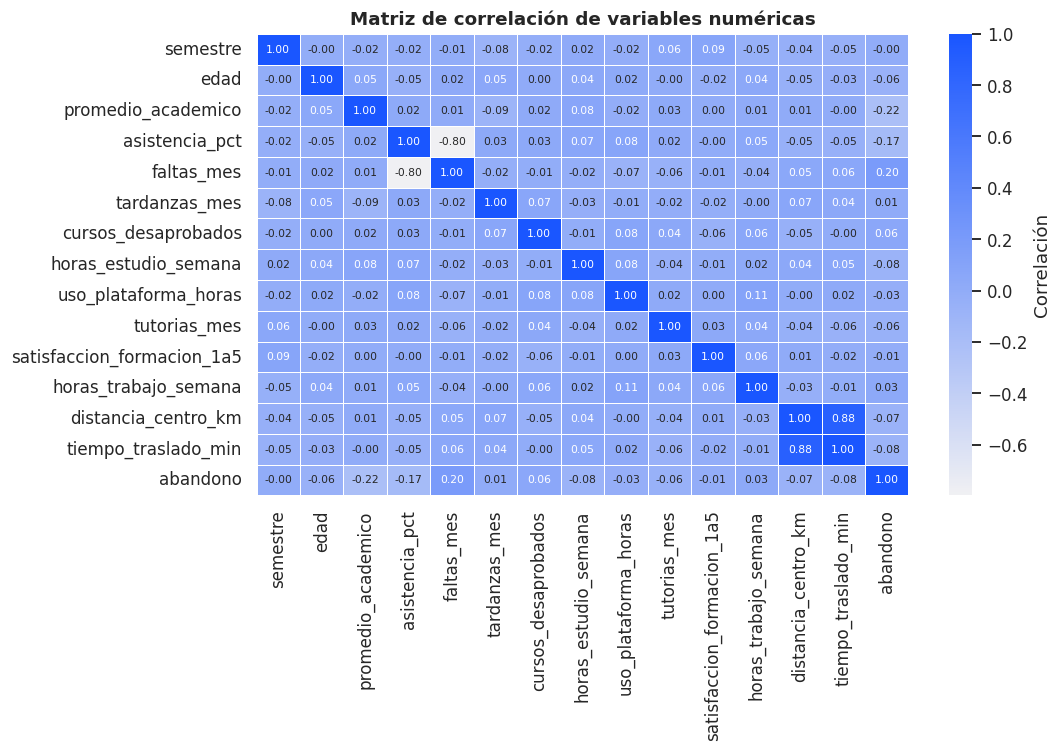

In [16]:
fig, ax = plt.subplots(figsize=(10, 7))
corr = df.select_dtypes("number").corr()
sns.heatmap(corr, cmap=sns.light_palette(AZUL, as_cmap=True), annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.5, ax=ax, cbar_kws={"label": "Correlación"})
ax.set_title("Matriz de correlación de variables numéricas"); guardar("06_matriz_correlacion")

**Interpretación:** `distancia_centro_km` y `tiempo_traslado_min` están muy correlacionadas entre sí (esperable, a mayor distancia mayor tiempo), igual que `faltas_mes` y `asistencia_pct`. Con el objetivo, las más relevantes son `promedio_academico`, `faltas_mes` y `asistencia_pct`. Estas redundancias justifican usar regularización.

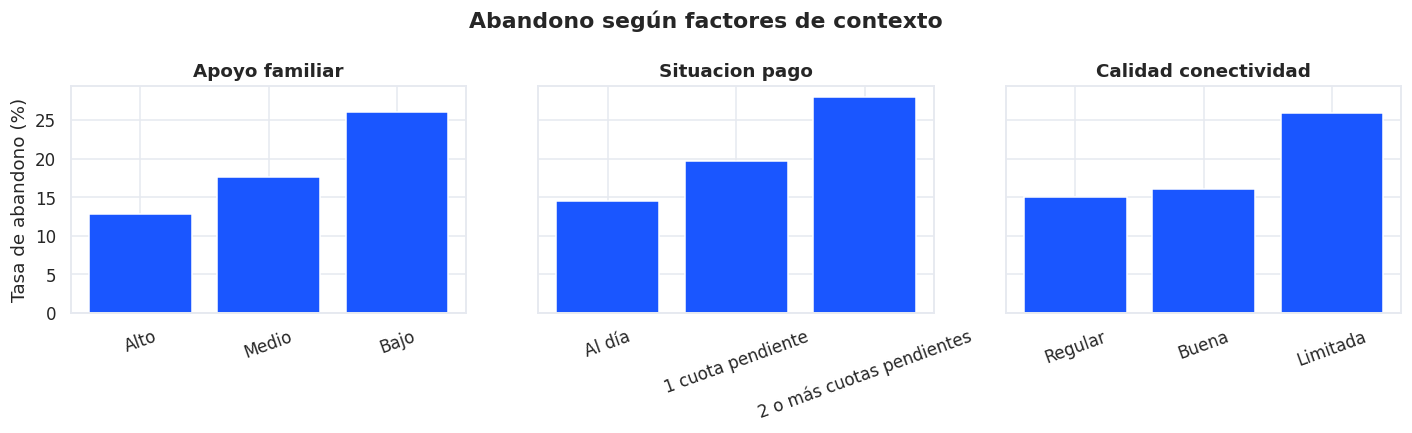

In [17]:
# Gráfico adicional: tasa de abandono por factor de contexto
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, col in zip(axes, ["apoyo_familiar", "situacion_pago", "calidad_conectividad"]):
    t = (df.groupby(col)["abandono"].mean() * 100).sort_values()
    ax.bar(t.index, t.values, color=AZUL)
    ax.set_title(col.replace("_", " ").capitalize()); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Tasa de abandono (%)")
fig.suptitle("Abandono según factores de contexto", fontweight="bold")
guardar("07_abandono_por_contexto")

**Interpretación:** el abandono casi se duplica con apoyo familiar bajo, con 2 o más cuotas pendientes y con conectividad limitada. Son factores **de contexto** que un tutor puede atender aunque el rendimiento académico aún sea aceptable.

# ETAPA 7 – MODELO DE MACHINE LEARNING

Se compara **Regresión Logística** (modelo base) con **Random Forest** usando validación cruzada estratificada sobre el conjunto de entrenamiento. Ambos usan `class_weight="balanced"` por el desbalance 5 a 1.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidatos = {
    "Regresión Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=42),
}
filas = []
for nombre, algoritmo in candidatos.items():
    pipe = Pipeline([("prep", preprocesador), ("modelo", algoritmo)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    filas.append({"modelo": nombre, **{m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
comparacion_cv = pd.DataFrame(filas).set_index("modelo").round(3)
print("Validación cruzada (5 folds) sobre el conjunto de entrenamiento:")
comparacion_cv

Validación cruzada (5 folds) sobre el conjunto de entrenamiento:


,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regresión Logística,0.696,0.283,0.538,0.368,0.672
Random Forest,0.825,0.400,0.075,0.123,0.681


### Interpretación – Comparación de modelos

La **Regresión Logística** logra un recall mucho mayor que el **Random Forest**, que con el umbral estándar de 0,5 casi no detecta casos de abandono (acierta por predecir "continúa" casi siempre). Con pocos datos (80 casos positivos en entrenamiento) el bosque tiende a memorizar; el modelo lineal, más simple y regularizado, generaliza mejor. Como en este problema **un falso negativo es el error más costoso**, se elige la Regresión Logística como modelo final.

In [19]:
# Ajuste del hiperparámetro C (regularización) maximizando el recall de la clase abandono
base = Pipeline([("prep", preprocesador),
                 ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))])
busqueda = GridSearchCV(base, {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
                        scoring="recall", cv=cv).fit(X_train, y_train)
print("Mejor C:", busqueda.best_params_["modelo__C"], "| Recall en validación cruzada: %.3f" % busqueda.best_score_)
pd.DataFrame(busqueda.cv_results_)[["param_modelo__C", "mean_test_score"]].rename(
    columns={"param_modelo__C": "C", "mean_test_score": "recall_cv"}).round(3)

Mejor C: 0.01 | Recall en validación cruzada: 0.613


,C,recall_cv
0,0.01,0.612
1,0.03,0.588
2,0.10,0.600
3,0.30,0.525
4,1.00,0.538
5,3.00,0.538


### Decisión sobre el hiperparámetro C

El recall en validación cruzada es casi igual para `C = 0,01` (0,612) y `C = 0,1` (0,600): la diferencia de 1 punto está dentro del ruido de una muestra tan pequeña. Sin embargo, con `C = 0,01` la regularización es tan fuerte que **casi todas las probabilidades quedan comprimidas cerca de 0,5**, y los niveles de riesgo (bajo, medio, alto) dejan de ser útiles. Se elige **`C = 0,1`**: mantiene el recall y conserva probabilidades con suficiente dispersión para separar niveles.

In [20]:
C_ELEGIDO = 0.1
modelo_final = Pipeline([("prep", preprocesador),
                         ("modelo", LogisticRegression(C=C_ELEGIDO, max_iter=2000, class_weight="balanced"))])
modelo_final.fit(X_train, y_train)               # Pipeline completo: preprocesamiento + regresión logística

y_pred = modelo_final.predict(X_test)                 # clase predicha
y_prob = modelo_final.predict_proba(X_test)[:, 1]     # probabilidad de abandono

metricas = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_prob),
}
print("MÉTRICAS EN EL CONJUNTO DE PRUEBA (120 estudiantes, 20 abandonan)")
for k, v in metricas.items():
    print(f"  {k:10s}: {v:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Continúa", "Abandona"]))

MÉTRICAS EN EL CONJUNTO DE PRUEBA (120 estudiantes, 20 abandonan)
  accuracy  : 0.758
  precision : 0.371
  recall    : 0.650
  f1        : 0.473
  roc_auc   : 0.742

              precision    recall  f1-score   support

    Continúa       0.92      0.78      0.84       100
    Abandona       0.37      0.65      0.47        20

    accuracy                           0.76       120
   macro avg       0.64      0.72      0.66       120
weighted avg       0.83      0.76      0.78       120



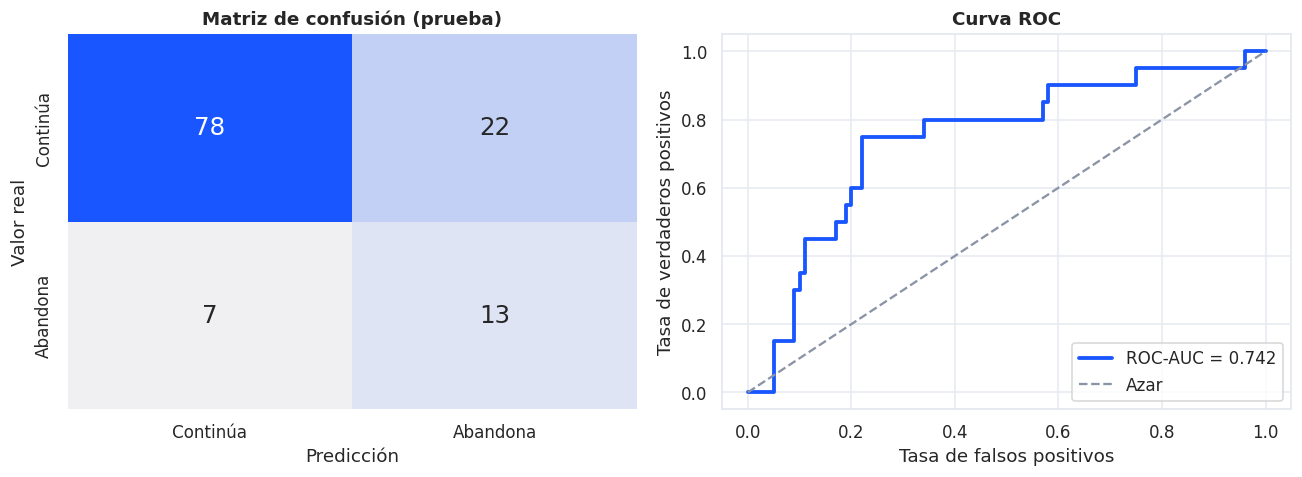

Verdaderos negativos: 78 | Falsos positivos: 22 | Falsos negativos: 7 | Verdaderos positivos: 13


In [21]:
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False, ax=axes[0],
            xticklabels=["Continúa", "Abandona"], yticklabels=["Continúa", "Abandona"], annot_kws={"size": 16})
axes[0].set_title("Matriz de confusión (prueba)"); axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("Valor real")

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color=AZUL, lw=2.5, label=f"ROC-AUC = {metricas['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], color=GRIS, ls="--", label="Azar")
axes[1].set_title("Curva ROC"); axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].legend(loc="lower right")
guardar("08_matriz_confusion_roc")
print("Verdaderos negativos:", cm[0,0], "| Falsos positivos:", cm[0,1], "| Falsos negativos:", cm[1,0], "| Verdaderos positivos:", cm[1,1])

### Interpretación – Métricas del modelo final

Sobre los 120 estudiantes de prueba (20 que abandonan):

- **Recall = 0,65:** el modelo detecta **13 de los 20** estudiantes que realmente abandonan. Es la métrica prioritaria.
- **Precision ≈ 0,37:** de cada 100 estudiantes marcados en riesgo, unos 37 abandonan realmente. Hay **22 falsos positivos**, es decir, alertas que el tutor revisará y que no terminan en abandono. Es un costo aceptable: revisar a un estudiante cuesta poco, perder a uno que se podía ayudar cuesta mucho.
- **Accuracy ≈ 0,76:** es menor que el 83 % de un modelo "ingenuo" que dice siempre "continúa", pero ese modelo tendría **recall = 0**, es decir, no serviría. Por eso no se evalúa solo con accuracy.
- **ROC-AUC ≈ 0,74:** el modelo ordena a los estudiantes con una capacidad **moderada** (0,5 sería azar, 1,0 perfecto). Es coherente con las correlaciones débiles observadas.
- **7 falsos negativos** siguen sin detectarse: es la limitación principal.

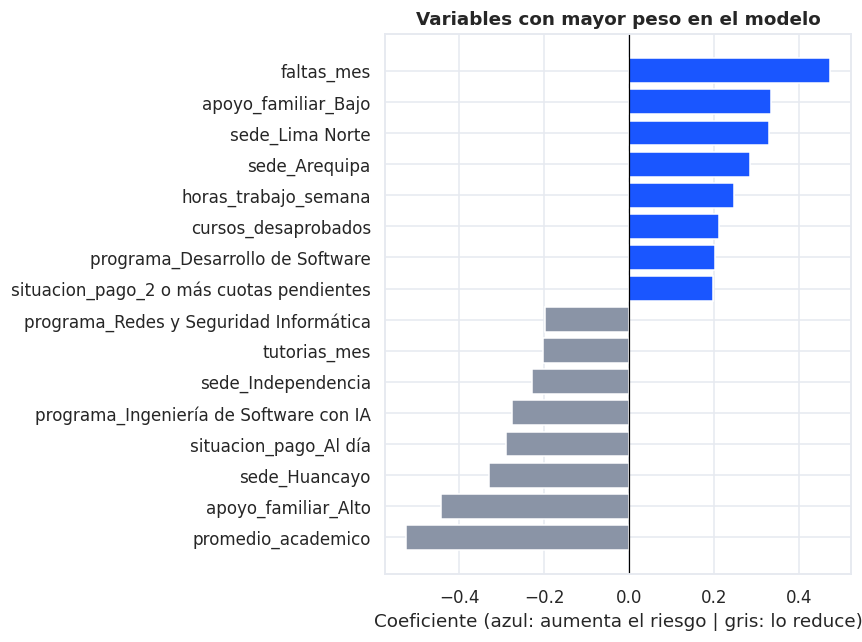

faltas_mes                                  0.473
apoyo_familiar_Bajo                         0.334
sede_Lima Norte                             0.328
sede_Arequipa                               0.283
horas_trabajo_semana                        0.247
cursos_desaprobados                         0.212
programa_Desarrollo de Software             0.202
situacion_pago_2 o más cuotas pendientes    0.198
programa_Redes y Seguridad Informática     -0.199
tutorias_mes                               -0.203
sede_Independencia                         -0.227
programa_Ingeniería de Software con IA     -0.276
situacion_pago_Al día                      -0.289
sede_Huancayo                              -0.329
apoyo_familiar_Alto                        -0.442
promedio_academico                         -0.524
dtype: float64

In [22]:
# Variables más influyentes: coeficientes de la regresión logística (sobre variables estandarizadas)
nombres = modelo_final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modelo_final.named_steps["modelo"].coef_[0], index=nombres)
coefs.index = [n.replace("num__", "").replace("cat__", "") for n in coefs.index]
top = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[AZUL if v > 0 else GRIS for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Variables con mayor peso en el modelo"); ax.set_xlabel("Coeficiente (azul: aumenta el riesgo | gris: lo reduce)")
guardar("09_coeficientes")
top.round(3).sort_values(ascending=False)

### Interpretación – Variables influyentes

Un coeficiente positivo (azul) **aumenta** la probabilidad de abandono y uno negativo (gris) la **reduce**. Se observa que el modelo aprovecha factores académicos (promedio, faltas, cursos desaprobados) y de contexto (apoyo familiar, cuotas pendientes, horas de trabajo y sede), en línea con el análisis exploratorio. Con estas variables estandarizadas, `promedio_academico` y `faltas_mes` son las de mayor peso. Es una ventaja de la Regresión Logística: **es interpretable**, algo valioso cuando los resultados serán usados por tutores y no solo por técnicos.

In [23]:
# Análisis de errores: ¿cómo son los falsos negativos (abandonan pero el modelo no los detectó)?
res = X_test.copy()
res["real"], res["pred"], res["prob"] = y_test.values, y_pred, y_prob
fn = res[(res.real == 1) & (res.pred == 0)]
tp = res[(res.real == 1) & (res.pred == 1)]
cols_cmp = ["promedio_academico", "asistencia_pct", "faltas_mes", "cursos_desaprobados", "tutorias_mes"]
comp = pd.DataFrame({"Falsos negativos (n=%d)" % len(fn): fn[cols_cmp].mean(),
                     "Verdaderos positivos (n=%d)" % len(tp): tp[cols_cmp].mean()}).round(2)
print(comp)
print("\nProbabilidad media asignada a los falsos negativos: %.2f" % fn["prob"].mean())

                     Falsos negativos (n=7)  Verdaderos positivos (n=13)
promedio_academico                    13.11                        11.45
asistencia_pct                        86.37                        76.04
faltas_mes                             1.57                         3.62
cursos_desaprobados                    0.57                         1.54
tutorias_mes                           1.86                         1.31

Probabilidad media asignada a los falsos negativos: 0.32


### Análisis de errores

Los falsos negativos tienen, en promedio, **mejor rendimiento y asistencia** que los verdaderos positivos: son estudiantes que abandonan por motivos que el dataset no captura (por ejemplo, razones personales o de salud). Ningún modelo puede detectar lo que no está en los datos. Esto refuerza que la herramienta es **apoyo para el tutor** y no reemplaza su criterio.

# ETAPA 8 – INTERPRETACIÓN DEL RIESGO

El sistema convierte la probabilidad en un nivel comprensible:

| Nivel | Probabilidad | Significado |
|---|---|---|
| **Riesgo bajo** | menor a 25 % | Seguimiento regular |
| **Riesgo medio** | de 25 % a menos de 50 % | Conversación preventiva con el tutor |
| **Riesgo alto** | 50 % o más | Revisión prioritaria y plan de apoyo |

Los rangos son una **decisión de diseño** y coinciden con el umbral de 0,5 usado por el modelo para clasificar. Como el entrenamiento usa `class_weight="balanced"`, el valor es un **índice de riesgo** (sirve para ordenar y agrupar estudiantes), no una probabilidad real calibrada de abandono.

In [24]:
def clasificar_riesgo(prob):
    if prob < 0.25:
        return "Bajo"
    elif prob < 0.50:
        return "Medio"
    return "Alto"

niveles = pd.Series([clasificar_riesgo(p) for p in y_prob], index=X_test.index)
tabla_riesgo = (pd.DataFrame({"nivel": niveles, "abandono_real": y_test})
                .groupby("nivel")["abandono_real"].agg(estudiantes="count", abandonan="sum", tasa_abandono="mean")
                .reindex(["Bajo", "Medio", "Alto"]))
tabla_riesgo["tasa_abandono"] = (tabla_riesgo["tasa_abandono"] * 100).round(1)
tabla_riesgo

,estudiantes,abandonan,tasa_abandono
nivel,,,
Bajo,37,2,5.4
Medio,48,5,10.4
Alto,35,13,37.1


### Interpretación

La tasa real de abandono **aumenta con cada nivel** de riesgo: 5,4 % en Bajo, 10,4 % en Medio y 37,1 % en Alto. Los niveles son coherentes y ayudan al tutor a priorizar (en el nivel Alto se abandona unas 7 veces más que en el Bajo), aunque con solo 120 estudiantes de prueba las cifras de Bajo y Medio son poco estables y siempre habrá casos que escapan, por eso el resultado se presenta como **apoyo para revisión académica y nunca como decisión definitiva** sobre el estudiante.

# GUARDADO DEL MODELO PARA FLASK

Se guarda el **pipeline completo** (preprocesamiento + modelo) en un `.pkl`, junto con un archivo `metricas.json` que la aplicación usará en la página "Información del modelo".

In [25]:
import joblib, sklearn

os.makedirs("../03_MODELO", exist_ok=True)
os.makedirs("../04_APLICATIVO/modelo", exist_ok=True)

joblib.dump(modelo_final, "../03_MODELO/modelo_desercion.pkl")
joblib.dump(modelo_final, "../04_APLICATIVO/modelo/modelo_desercion.pkl")

info = {
    "algoritmo": "Regresión Logística (class_weight=balanced, C=%s)" % C_ELEGIDO,
    "version": "1.0",
    "fecha_entrenamiento": datetime.date.today().isoformat(),
    "version_sklearn": sklearn.__version__,
    "registros_totales": int(len(df)),
    "registros_entrenamiento": int(len(X_train)),
    "registros_prueba": int(len(X_test)),
    "variables_numericas": cols_num,
    "variables_categoricas": cols_cat,
    "metricas_prueba": {k: round(float(v), 3) for k, v in metricas.items()},
    "matriz_confusion": cm.tolist(),
    "comparacion_validacion_cruzada": comparacion_cv.reset_index().to_dict(orient="records"),
    "variables_que_aumentan_riesgo": [n for n in coefs.sort_values(ascending=False).head(5).index],
    "variables_que_reducen_riesgo": [n for n in coefs.sort_values().head(5).index],
    "umbrales_riesgo": {"bajo_menor_a": 0.25, "alto_desde": 0.50},
}
for ruta_json in ["../03_MODELO/metricas.json", "../04_APLICATIVO/modelo/metricas.json"]:
    with open(ruta_json, "w", encoding="utf-8") as f:
        json.dump(info, f, ensure_ascii=False, indent=2)

# Verificación: cargar el .pkl y predecir un estudiante nuevo, como hará Flask
cargado = joblib.load("../03_MODELO/modelo_desercion.pkl")
ejemplo = X_test.iloc[[0]]
p = cargado.predict_proba(ejemplo)[0, 1]
print("Modelo guardado y verificado ✔")
print("Probabilidad del primer estudiante de prueba: %.1f %% → riesgo %s" % (p * 100, clasificar_riesgo(p)))

Modelo guardado y verificado ✔
Probabilidad del primer estudiante de prueba: 44.9 % → riesgo Medio


# CONCLUSIONES DEL CUADERNO

1. El dataset (600 registros, 16,7 % de abandono) está **desbalanceado** y tiene pocos nulos, tratados con imputación dentro del pipeline.
2. Los factores asociados al abandono son **académicos** (promedio, faltas, asistencia) y de **contexto** (apoyo familiar, cuotas pendientes, conectividad).
3. La **Regresión Logística** superó al Random Forest en la métrica prioritaria (recall) y es interpretable.
4. El modelo detecta cerca de dos de cada tres casos de abandono con un ROC-AUC moderado (~0,74). Sirve como **herramienta de apoyo**, no como decisión automática.
5. El pipeline completo quedó guardado en `modelo_desercion.pkl` y es consumido por la aplicación Flask.

**Limitaciones:** datos sintéticos, muestra pequeña (20 casos positivos en prueba, por lo que las métricas tienen incertidumbre) y ausencia de variables personales o de salud. Antes de un uso real se necesitaría validar con datos reales, evaluar equidad entre sedes y programas, y recalibrar las probabilidades.